<a href="https://colab.research.google.com/github/cotri77/proyecto_abandono_escolar/blob/main/EduFuture_abandono_escolarII.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎓 EduFuture · Predicción de abandono escolar con regresión logística

**Objetivo:** construir un modelo de clasificación que estime la probabilidad de que un estudiante
interrumpa sus estudios en los 12 meses siguientes (`abandono_en_12_meses = 1`), para que EduFuture
pueda ofrecer **apoyo preventivo** a tiempo.

**Índice**
1. Librerías
2. Carga de datos
3. Análisis exploratorio (EDA) y limpieza
4. Selección de variables
5. Ingeniería de características (codificación y escalado)
6. Entrenamiento del modelo y ajuste con validación
7. Elección del umbral de decisión
8. Evaluación final en el conjunto de prueba
9. Interpretación de los coeficientes
10. Auditoría de equidad
11. Conclusiones y recomendaciones

> ⚠️ El dataset es **sintético** (2.400 estudiantes simulados con fines académicos). No representa
> estudiantes reales ni sirve para estimar tasas reales de abandono.

## 1. Librerías

- `pandas` y `numpy`: trabajar con tablas y números.
- `matplotlib` y `seaborn`: hacer gráficos.
- `scikit-learn`: preparar los datos, entrenar el modelo y medir sus resultados.

In [1]:
# --- CELDA 1: librerías ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Herramientas de scikit-learn para preparar los datos y crear el modelo
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Métricas para evaluar el modelo
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Colores de los gráficos: azul = continúa, naranja = abandona
COLOR_CONTINUA = "#4C72B0"
COLOR_ABANDONA = "#DD8452"
PALETA = {0: COLOR_CONTINUA, 1: COLOR_ABANDONA}

## 2. Carga de datos

Al ejecutar la celda aparece el botón **"Elegir archivos"**: selecciona el Excel
`edufuture_dataset_abandono_escolar_sintetico.xlsx` en tu ordenador.

In [2]:
# --- CELDA 2: subir y leer el Excel ---
from google.colab import files
files.upload()   # aparece el botón "Elegir archivos"

ruta = "edufuture_dataset_abandono_escolar_sintetico.xlsx"
df = pd.read_excel(ruta, sheet_name="01_Datos")   # los datos están en la hoja 01_Datos
df.head()

Saving edufuture_dataset_abandono_escolar_sintetico.xlsx to edufuture_dataset_abandono_escolar_sintetico.xlsx


,id_estudiante,curso_academico,fecha_corte,comunidad_autonoma,entorno_municipio,titularidad_centro,etapa,curso_nivel,edad_anios,sexo_declarado,...,utilidad_percibida_estudios_1_5,pertenencia_centro_1_5,relacion_docentes_1_5,acoso_ultimos_30_dias,bienestar_autopercibido_1_5,apoyo_familiar_estudios_1_5,intencion_continuar_estudios_1_5,contacto_tutoria_hasta_corte,abandono_en_12_meses,particion_sugerida
0,EF0001,2025-2026,2025-10-15,Castilla y León,Rural,Concertado,4º ESO,4º ESO,17,Mujer,...,1,1,2,Varias veces al mes,3,2,3,1,0,entrenamiento
1,EF0002,2025-2026,2025-10-15,Extremadura,Urbano,Privado,Bachillerato,1º Bachillerato,16,Mujer,...,3,3,3,Varias veces al mes,3,2,2,1,0,entrenamiento
2,EF0003,2025-2026,2025-10-15,País Vasco,Urbano,Público,4º ESO,4º ESO,15,Hombre,...,4,4,3,Nunca,2,3,4,1,0,prueba
3,EF0004,2025-2026,2025-10-15,Andalucía,Urbano,Público,CFGM,1º CFGM,17,Mujer,...,4,3,3,Una vez,4,1,4,0,0,validacion
4,EF0005,2025-2026,2025-10-15,Región de Murcia,Urbano,Público,Bachillerato,2º Bachillerato,18,Mujer,...,2,2,2,Varias veces al mes,2,2,2,0,0,entrenamiento


In [3]:
# --- CELDA 3: diccionario de variables (hoja 02_Diccionario) ---
# Las dos primeras filas de la hoja son título y leyenda, por eso usamos header=2
diccionario = pd.read_excel(ruta, sheet_name="02_Diccionario", header=2)
diccionario[["Variable", "Tipo", "Valores o rango", "Rol recomendado"]]

,Variable,Tipo,Valores o rango,Rol recomendado
0,id_estudiante,Texto,EF0001...,Excluir
1,curso_academico,Texto,2025-2026,Excluir
2,fecha_corte,Fecha,2025-10-15,Excluir
3,comunidad_autonoma,Categórica,18 categorías,Solo auditoría
4,entorno_municipio,Categórica,Urbano; Intermedio; Rural,Predictor opcional
5,titularidad_centro,Categórica,Público; Concertado; Privado,Solo auditoría
6,etapa,Categórica,4º ESO; Bachillerato; FP Básica; CFGM,Predictor
7,curso_nivel,Categórica,4º ESO; 1º/2º Bach.; 1º/2º FP,Predictor
8,edad_anios,Numérica,15 a 21,Predictor
9,sexo_declarado,Categórica,Mujer; Hombre; No binario; No responde,Solo auditoría


## 3. Análisis exploratorio (EDA) y limpieza

### 3.1 Estructura, tipos de datos, nulos y duplicados

In [4]:
# --- CELDA 4: tipos de datos y valores nulos ---
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "valores_distintos": df.nunique(),
})
print("Total de valores nulos en el dataset:", df.isna().sum().sum())
print("Filas duplicadas (ignorando el id):", df.drop(columns="id_estudiante").duplicated().sum())
print("Identificadores repetidos:", df["id_estudiante"].duplicated().sum())
resumen

Total de valores nulos en el dataset: 0
Filas duplicadas (ignorando el id): 0
Identificadores repetidos: 0


,tipo,nulos,valores_distintos
id_estudiante,object,0,2400
curso_academico,object,0,1
fecha_corte,object,0,1
comunidad_autonoma,object,0,18
entorno_municipio,object,0,3
titularidad_centro,object,0,3
etapa,object,0,4
curso_nivel,object,0,7
edad_anios,int64,0,7
sexo_declarado,object,0,4


**Conclusión:** no hay valores nulos ni registros duplicados, así que **no hace falta imputar ni
eliminar filas**. La limpieza se centra en **validar** que los valores son coherentes.

In [5]:
# --- CELDA 5: estadísticos descriptivos de las variables numéricas ---
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
edad_anios,2400.0,17.10,1.19,15.0,16.0,17.0,18.00,21.0
nacido_fuera_espana,2400.0,0.14,0.35,0.0,0.0,0.0,0.00,1.0
convive_con_progenitor,2400.0,0.91,0.28,0.0,1.0,1.0,1.00,1.0
necesidad_apoyo_educativo,2400.0,0.11,0.31,0.0,0.0,0.0,0.00,1.0
dificultad_economica_hogar_1_5,2400.0,2.61,1.10,1.0,2.0,3.0,3.00,5.0
internet_estable_hogar,2400.0,0.93,0.26,0.0,1.0,1.0,1.00,1.0
espacio_adecuado_estudio,2400.0,0.77,0.42,0.0,1.0,1.0,1.00,1.0
horas_trabajo_remunerado_semana,2400.0,2.18,2.26,0.0,0.0,2.0,4.00,13.0
horas_cuidados_familiares_semana,2400.0,2.07,2.14,0.0,0.0,2.0,3.25,11.0
asistencia_ultimos_30_dias_pct,2400.0,89.44,10.69,45.3,82.6,91.7,100.00,100.0


### 3.2 Validación de rangos, binarias y categorías

In [6]:
# --- CELDA 6: comprobación de rangos según el diccionario ---
# Para cada variable indicamos el rango (mínimo, máximo) que debería cumplir
rangos_esperados = {
    "edad_anios": (15, 21),
    "asistencia_ultimos_30_dias_pct": (45, 100),
    "nota_media_trimestre_anterior_0_10": (2.5, 10),
    "materias_suspensas_trimestre_anterior": (0, 8),
    "retrasos_ultimos_30_dias": (0, 18),
    "horas_trabajo_remunerado_semana": (0, 24),
    "horas_cuidados_familiares_semana": (0, 25),
    "horas_estudio_semana": (0, 30),
}
# Todas las escalas tipo Likert van de 1 a 5
for col in df.columns:
    if col.endswith("_1_5"):
        rangos_esperados[col] = (1, 5)

for col, (minimo, maximo) in rangos_esperados.items():
    fuera = ((df[col] < minimo) | (df[col] > maximo)).sum()
    estado = "✅" if fuera == 0 else "❌"
    print(f"{estado} {col:40s} rango [{minimo}, {maximo}]  ->  valores fuera: {fuera}")

✅ edad_anios                               rango [15, 21]  ->  valores fuera: 0
✅ asistencia_ultimos_30_dias_pct           rango [45, 100]  ->  valores fuera: 0
✅ nota_media_trimestre_anterior_0_10       rango [2.5, 10]  ->  valores fuera: 0
✅ materias_suspensas_trimestre_anterior    rango [0, 8]  ->  valores fuera: 0
✅ retrasos_ultimos_30_dias                 rango [0, 18]  ->  valores fuera: 0
✅ horas_trabajo_remunerado_semana          rango [0, 24]  ->  valores fuera: 0
✅ horas_cuidados_familiares_semana         rango [0, 25]  ->  valores fuera: 0
✅ horas_estudio_semana                     rango [0, 30]  ->  valores fuera: 0
✅ dificultad_economica_hogar_1_5           rango [1, 5]  ->  valores fuera: 0
✅ satisfaccion_programa_1_5                rango [1, 5]  ->  valores fuera: 0
✅ utilidad_percibida_estudios_1_5          rango [1, 5]  ->  valores fuera: 0
✅ pertenencia_centro_1_5                   rango [1, 5]  ->  valores fuera: 0
✅ relacion_docentes_1_5                    rango [1,

In [7]:
# --- CELDA 7: las variables binarias solo deben contener 0 y 1 ---
binarias = ["nacido_fuera_espana", "convive_con_progenitor", "necesidad_apoyo_educativo",
            "internet_estable_hogar", "espacio_adecuado_estudio", "ha_repetido_curso",
            "contacto_tutoria_hasta_corte", "abandono_en_12_meses"]
for col in binarias:
    valores = sorted(int(v) for v in df[col].unique())
    print(f"{'✅' if valores == [0, 1] else '❌'} {col:32s} valores: {valores}")

✅ nacido_fuera_espana              valores: [0, 1]
✅ convive_con_progenitor           valores: [0, 1]
✅ necesidad_apoyo_educativo        valores: [0, 1]
✅ internet_estable_hogar           valores: [0, 1]
✅ espacio_adecuado_estudio         valores: [0, 1]
✅ ha_repetido_curso                valores: [0, 1]
✅ contacto_tutoria_hasta_corte     valores: [0, 1]
✅ abandono_en_12_meses             valores: [0, 1]


In [8]:
# --- CELDA 8: categorías de las variables de texto ---
categoricas = ["etapa", "curso_nivel", "entorno_municipio", "titularidad_centro",
               "max_estudios_progenitores", "acoso_ultimos_30_dias", "sexo_declarado"]
for col in categoricas:
    print(f"\n{col}:")
    print(df[col].value_counts().to_string())


etapa:
etapa
Bachillerato    806
CFGM            758
4º ESO          643
FP Básica       193

curso_nivel:
curso_nivel
4º ESO             643
1º CFGM            426
1º Bachillerato    422
2º Bachillerato    384
2º CFGM            332
1º FP Básica       107
2º FP Básica        86

entorno_municipio:
entorno_municipio
Urbano        1588
Intermedio     513
Rural          299

titularidad_centro:
titularidad_centro
Público       1572
Concertado     677
Privado        151

max_estudios_progenitores:
max_estudios_progenitores
Secundaria postobligatoria o FP    829
ESO o equivalente                  746
Educación superior                 567
Primaria o inferior                258

acoso_ultimos_30_dias:
acoso_ultimos_30_dias
Nunca                       714
Una vez                     698
Una vez por semana o más    512
Varias veces al mes         476

sexo_declarado:
sexo_declarado
Mujer                    1173
Hombre                   1173
No binario                 33
Prefiere no responder

In [9]:
# --- CELDA 9: coherencia entre etapa y curso_nivel ---
# Cada curso debería pertenecer a una única etapa
pd.crosstab(df["curso_nivel"], df["etapa"])

etapa,4º ESO,Bachillerato,CFGM,FP Básica
curso_nivel,,,,
1º Bachillerato,0,422,0,0
1º CFGM,0,0,426,0
1º FP Básica,0,0,0,107
2º Bachillerato,0,384,0,0
2º CFGM,0,0,332,0
2º FP Básica,0,0,0,86
4º ESO,643,0,0,0


**Conclusión:** todos los valores están dentro de los rangos del diccionario, las binarias usan 0/1 y
las categorías coinciden. Además, `curso_nivel` está **anidado** dentro de `etapa` (cada curso
pertenece a una sola etapa). Lo tendremos en cuenta en la ingeniería de características para no
introducir información duplicada.

### 3.3 Variable objetivo: ¿cuántos estudiantes abandonan?

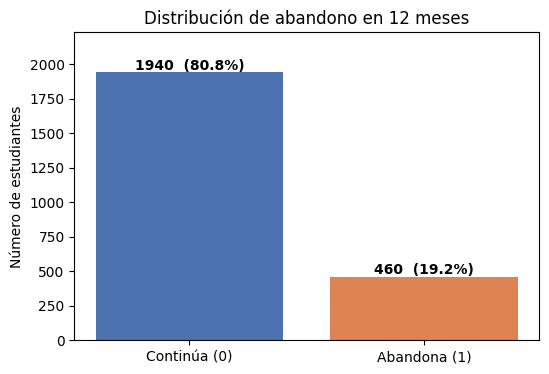

In [10]:
# --- CELDA 10: distribución de la variable objetivo ---
conteo = df["abandono_en_12_meses"].value_counts().sort_index()
porcentaje = df["abandono_en_12_meses"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(["Continúa (0)", "Abandona (1)"], conteo.values,
                color=[COLOR_CONTINUA, COLOR_ABANDONA])
for barra, n, p in zip(barras, conteo.values, porcentaje.values):
    ax.text(barra.get_x() + barra.get_width() / 2, n + 20, f"{n}  ({p:.1f}%)",
            ha="center", fontweight="bold")
ax.set_title("Distribución de abandono en 12 meses")
ax.set_ylabel("Número de estudiantes")
ax.set_ylim(0, conteo.max() * 1.15)
plt.show()

**Conclusión:** el **19,2 %** de los estudiantes abandona. Las clases están **desbalanceadas**
(≈ 4 continúan por cada 1 que abandona). Esto tiene dos consecuencias:

1. El *accuracy* engaña: un modelo que dijera siempre "continúa" acertaría el 81 %… sin detectar a
   ningún estudiante en riesgo.
2. Daremos prioridad al **recall** (detectar el máximo de abandonos reales) y compensaremos el
   desbalance con `class_weight="balanced"`.

### 3.4 Tasa de abandono por etapa educativa

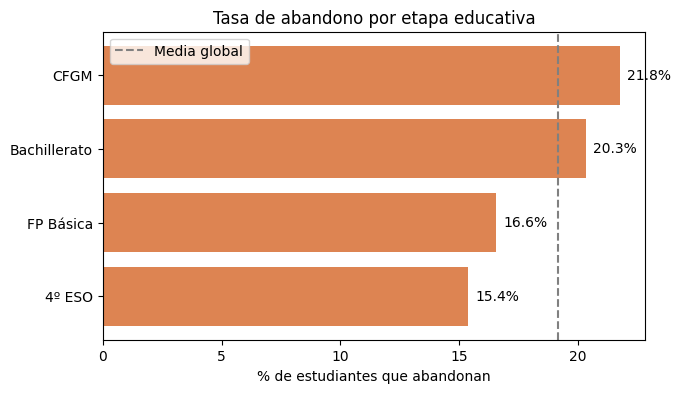

In [11]:
# --- CELDA 11: tasa de abandono por etapa ---
tasa_etapa = (df.groupby("etapa")["abandono_en_12_meses"].mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(tasa_etapa.index, tasa_etapa.values, color=COLOR_ABANDONA)
ax.axvline(df["abandono_en_12_meses"].mean() * 100, color="grey", ls="--", label="Media global")
for i, v in enumerate(tasa_etapa.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
ax.set_title("Tasa de abandono por etapa educativa")
ax.set_xlabel("% de estudiantes que abandonan")
ax.legend()
plt.show()

### 3.5 Variables académicas según el resultado

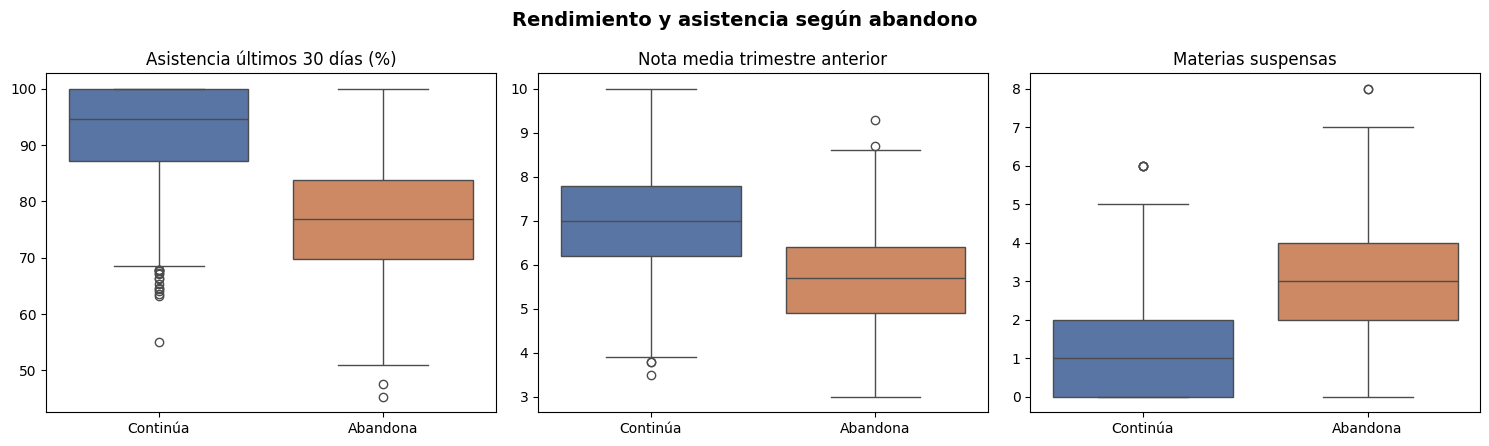

,asistencia_ultimos_30_dias_pct,nota_media_trimestre_anterior_0_10,materias_suspensas_trimestre_anterior
abandono_en_12_meses,,,
0,92.38,6.99,1.27
1,77.05,5.67,3.00


In [12]:
# --- CELDA 12: asistencia, nota y suspensos separados por resultado ---
variables_clave = {
    "asistencia_ultimos_30_dias_pct": "Asistencia últimos 30 días (%)",
    "nota_media_trimestre_anterior_0_10": "Nota media trimestre anterior",
    "materias_suspensas_trimestre_anterior": "Materias suspensas",
}
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, titulo) in zip(ejes, variables_clave.items()):
    sns.boxplot(data=df, x="abandono_en_12_meses", y=col, hue="abandono_en_12_meses",
                palette=PALETA, legend=False, ax=ax)
    ax.set_xticks([0, 1], ["Continúa", "Abandona"])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(titulo)
fig.suptitle("Rendimiento y asistencia según abandono", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Medias por grupo para poner cifras a lo que vemos
df.groupby("abandono_en_12_meses")[list(variables_clave)].mean().round(2)

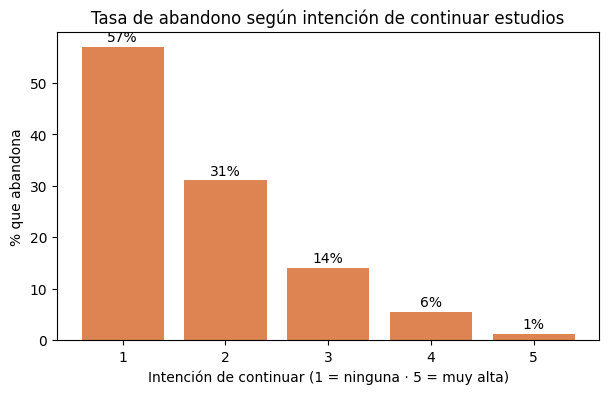

In [13]:
# --- CELDA 13: tasa de abandono según la intención de continuar (escala 1-5) ---
tasa_intencion = df.groupby("intencion_continuar_estudios_1_5")["abandono_en_12_meses"].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tasa_intencion.index.astype(str), tasa_intencion.values, color=COLOR_ABANDONA)
for i, v in enumerate(tasa_intencion.values):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")
ax.set_title("Tasa de abandono según intención de continuar estudios")
ax.set_xlabel("Intención de continuar (1 = ninguna · 5 = muy alta)")
ax.set_ylabel("% que abandona")
plt.show()

### 3.6 Correlación de las variables numéricas con el abandono

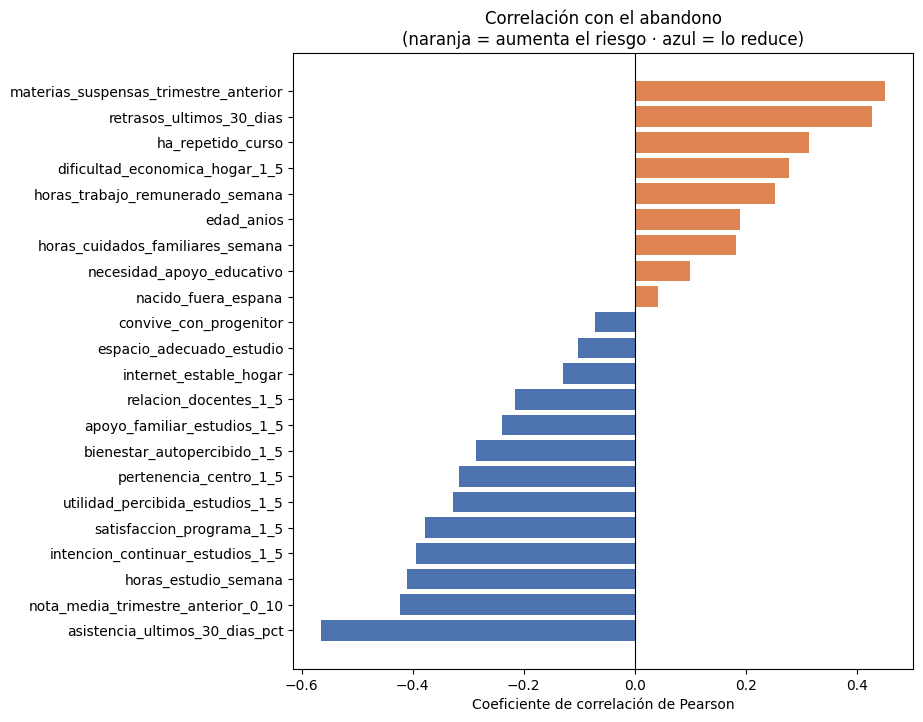

In [14]:
# --- CELDA 14: correlación de cada variable numérica con el abandono ---
columnas_excluir = ["abandono_en_12_meses", "contacto_tutoria_hasta_corte"]
correlaciones = (df.select_dtypes("number")
                   .drop(columns=columnas_excluir)
                   .corrwith(df["abandono_en_12_meses"])
                   .sort_values())

fig, ax = plt.subplots(figsize=(8, 8))
colores = [COLOR_ABANDONA if c > 0 else COLOR_CONTINUA for c in correlaciones]
ax.barh(correlaciones.index, correlaciones.values, color=colores)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlación con el abandono\n(naranja = aumenta el riesgo · azul = lo reduce)")
ax.set_xlabel("Coeficiente de correlación de Pearson")
plt.show()

**Conclusión:** las señales más fuertes son la **asistencia**, la **nota media**, las **horas de
estudio**, la **intención de continuar** y la **satisfacción** (protegen), frente a los **suspensos**,
los **retrasos**, la **repetición** y la **dificultad económica** (aumentan el riesgo).

### 3.7 Valores extremos (outliers)

Usamos la regla del **rango intercuartílico (IQR)**: un valor es extremo si está por debajo de
`Q1 − 1,5·IQR` o por encima de `Q3 + 1,5·IQR`.

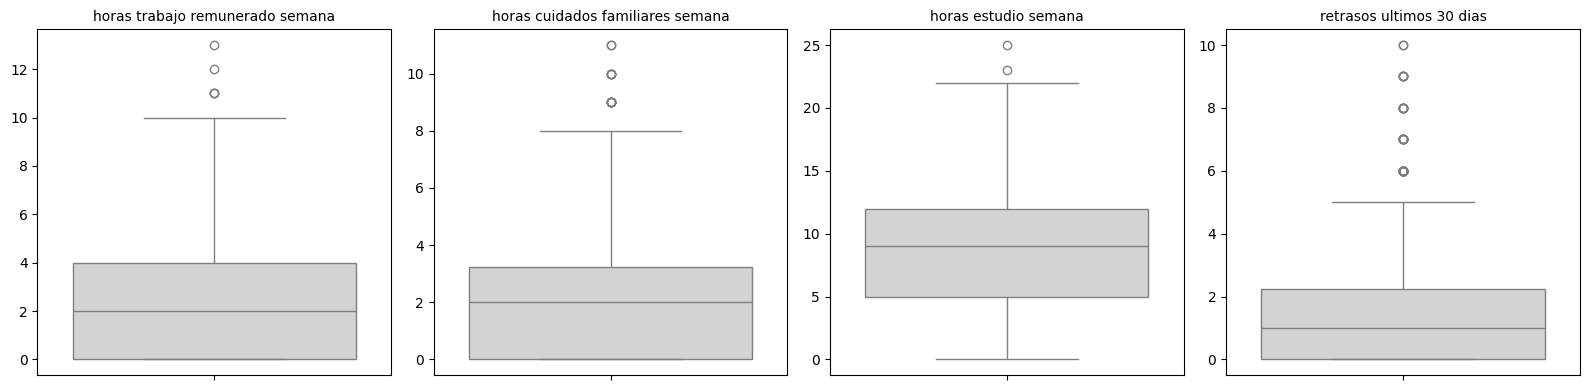

,variable,límite superior IQR,máximo observado,nº outliers,% outliers
0,horas_trabajo_remunerado_semana,10.000,13,5,0.2
1,horas_cuidados_familiares_semana,8.125,11,14,0.6
2,horas_estudio_semana,22.500,25,2,0.1
3,retrasos_ultimos_30_dias,5.625,10,70,2.9


In [15]:
# --- CELDA 15: detección de outliers con la regla IQR ---
variables_horas = ["horas_trabajo_remunerado_semana", "horas_cuidados_familiares_semana",
                   "horas_estudio_semana", "retrasos_ultimos_30_dias"]
filas = []
for col in variables_horas:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_sup = q3 + 1.5 * iqr
    n_outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > limite_sup)).sum()
    filas.append({"variable": col, "límite superior IQR": limite_sup,
                  "máximo observado": df[col].max(), "nº outliers": n_outliers,
                  "% outliers": round(n_outliers / len(df) * 100, 1)})
tabla_outliers = pd.DataFrame(filas)

fig, ejes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(ejes, variables_horas):
    sns.boxplot(y=df[col], ax=ax, color="lightgrey")
    ax.set_title(col.replace("_", " "), fontsize=10)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()
tabla_outliers

**Decisión sobre outliers: los mantenemos.**

- Son pocos (menos del 3 % en cada variable) y todos están dentro del rango válido del diccionario.
- Son **casos reales y plausibles** (por ejemplo, un estudiante que trabaja 13 h/semana) y
  precisamente pueden ser los de mayor riesgo. Eliminarlos haría que el modelo ignorase a quienes
  más apoyo necesitan.
- El escalado estándar posterior evita que su magnitud domine el modelo.

## 4. Selección de variables

Seguimos el **rol recomendado** del diccionario:

| Grupo | Variables | ¿Entra al modelo? | Motivo |
|---|---|---|---|
| Identificadores y técnicas | `id_estudiante`, `curso_academico`, `fecha_corte`, `particion_sugerida` | ❌ | No aportan información predictiva (o son constantes) |
| Intervención previa | `contacto_tutoria_hasta_corte` | ❌ | Es una acción ya iniciada: confundiría la interpretación |
| Auditoría de equidad | `sexo_declarado`, `nacido_fuera_espana`, `necesidad_apoyo_educativo`, `titularidad_centro`, `comunidad_autonoma` | ❌ | Variables sensibles: **no** deben decidir quién recibe apoyo. Se usan después para comprobar que el modelo es justo |
| Solo acompañamiento | `convive_con_progenitor` | ❌ | Orienta el apoyo social, no decisiones automáticas |
| Predictores y predictores opcionales | rendimiento, asistencia, contexto, vínculo con el centro… | ✅ | Señales tempranas y, en su mayoría, **modificables** |

In [16]:
# --- CELDA 16: definición de las listas de variables ---
OBJETIVO = "abandono_en_12_meses"

# Variables categóricas nominales -> one-hot encoding
VARIABLES_CATEGORICAS = ["etapa", "entorno_municipio", "max_estudios_progenitores"]

# Variables numéricas (incluye binarias, escalas 1-5 y las dos que creamos en la sección 5)
VARIABLES_NUMERICAS = [
    # Rendimiento y asistencia
    "asistencia_ultimos_30_dias_pct", "retrasos_ultimos_30_dias",
    "materias_suspensas_trimestre_anterior", "nota_media_trimestre_anterior_0_10",
    "ha_repetido_curso", "horas_estudio_semana",
    # Contexto y carga
    "edad_anios", "segundo_curso", "dificultad_economica_hogar_1_5",
    "internet_estable_hogar", "espacio_adecuado_estudio",
    "horas_trabajo_remunerado_semana", "horas_cuidados_familiares_semana",
    # Vínculo educativo y bienestar
    "satisfaccion_programa_1_5", "utilidad_percibida_estudios_1_5",
    "pertenencia_centro_1_5", "relacion_docentes_1_5", "acoso_frecuencia_0_3",
    "bienestar_autopercibido_1_5", "apoyo_familiar_estudios_1_5",
    "intencion_continuar_estudios_1_5",
]

# Variables que NO entran al modelo, pero que usaremos en la auditoría de equidad
VARIABLES_AUDITORIA = ["sexo_declarado", "nacido_fuera_espana", "necesidad_apoyo_educativo",
                       "titularidad_centro", "comunidad_autonoma"]

PREDICTORAS = VARIABLES_NUMERICAS + VARIABLES_CATEGORICAS
print(f"Usaremos {len(PREDICTORAS)} variables predictoras "
      f"({len(VARIABLES_NUMERICAS)} numéricas + {len(VARIABLES_CATEGORICAS)} categóricas)")

Usaremos 24 variables predictoras (21 numéricas + 3 categóricas)


## 5. Ingeniería de características

### 5.1 Nuevas variables
1. **`segundo_curso`** (0/1): como `curso_nivel` ya contiene la etapa, hacer one-hot de las dos
   variables crearía columnas redundantes (*multicolinealidad*). Nos quedamos con la etapa y con un
   indicador de si el alumno está en **segundo curso**.
2. **`acoso_frecuencia_0_3`**: la frecuencia de acoso es una variable **ordinal** (hay un orden
   natural), así que la convertimos en número de 0 a 3 en lugar de hacer one-hot.

In [17]:
# --- CELDA 17: creación de nuevas variables ---
def preparar_variables(datos):
    """Crea las variables derivadas. Devuelve una copia para no modificar el original."""
    datos = datos.copy()
    # 1 si el curso empieza por "2" (2º Bachillerato, 2º CFGM, 2º FP Básica); 4º ESO = 0
    datos["segundo_curso"] = datos["curso_nivel"].str.startswith("2").astype(int)
    # Codificación ordinal de la frecuencia de acoso
    orden_acoso = {"Nunca": 0, "Una vez": 1, "Varias veces al mes": 2,
                   "Una vez por semana o más": 3}
    datos["acoso_frecuencia_0_3"] = datos["acoso_ultimos_30_dias"].map(orden_acoso)
    return datos

df_modelo = preparar_variables(df)

# Comprobación: ningún valor de acoso se ha quedado sin traducir
assert df_modelo["acoso_frecuencia_0_3"].isna().sum() == 0, "Hay categorías de acoso sin mapear"
df_modelo[["curso_nivel", "segundo_curso", "acoso_ultimos_30_dias", "acoso_frecuencia_0_3"]].drop_duplicates().head(8)

,curso_nivel,segundo_curso,acoso_ultimos_30_dias,acoso_frecuencia_0_3
0,4º ESO,0,Varias veces al mes,2
1,1º Bachillerato,0,Varias veces al mes,2
2,4º ESO,0,Nunca,0
3,1º CFGM,0,Una vez,1
4,2º Bachillerato,1,Varias veces al mes,2
5,1º CFGM,0,Nunca,0
6,4º ESO,0,Una vez,1
7,4º ESO,0,Una vez por semana o más,3


### 5.2 División en entrenamiento, validación y prueba

El dataset trae una columna `particion_sugerida` ya **estratificada** (misma proporción de abandono en
cada parte). La respetamos:

- **Entrenamiento (70 %)** → el modelo aprende.
- **Validación (15 %)** → comparamos versiones del modelo y elegimos el umbral.
- **Prueba (15 %)** → solo se usa **una vez al final** para medir el rendimiento real.

In [18]:
# --- CELDA 18: separación de los tres conjuntos ---
entrenamiento = df_modelo[df_modelo["particion_sugerida"] == "entrenamiento"]
validacion    = df_modelo[df_modelo["particion_sugerida"] == "validacion"]
prueba        = df_modelo[df_modelo["particion_sugerida"] == "prueba"]

X_train, y_train = entrenamiento[PREDICTORAS], entrenamiento[OBJETIVO]
X_val,   y_val   = validacion[PREDICTORAS],    validacion[OBJETIVO]
X_test,  y_test  = prueba[PREDICTORAS],        prueba[OBJETIVO]

for nombre, y in [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]:
    print(f"{nombre:14s} {len(y):5d} filas  ·  abandono = {y.mean():.1%}")

Entrenamiento   1680 filas  ·  abandono = 19.2%
Validación       360 filas  ·  abandono = 19.2%
Prueba           360 filas  ·  abandono = 19.2%


### 5.3 Codificación y escalado con un `Pipeline`

- **`StandardScaler`** en las numéricas: las pone en la misma escala (media 0, desviación 1). Así los
  coeficientes de la regresión logística son **comparables** entre sí.
- **`OneHotEncoder(drop="first")`** en las categóricas: crea una columna 0/1 por categoría y elimina
  la primera, que queda como **categoría de referencia**.

Lo metemos todo en un **`Pipeline`**: el escalador aprende la media y la desviación **solo con los
datos de entrenamiento** y aplica esas mismas cifras a validación y prueba. Así evitamos la
**fuga de información** (*data leakage*).

In [19]:
# --- CELDA 19: preprocesador ---
def crear_preprocesador():
    return ColumnTransformer(transformers=[
        ("num", StandardScaler(), VARIABLES_NUMERICAS),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), VARIABLES_CATEGORICAS),
    ])

def crear_modelo(C=1.0, class_weight=None):
    """Pipeline completo: preprocesado + regresión logística."""
    return Pipeline(steps=[
        ("preprocesado", crear_preprocesador()),
        ("regresion", LogisticRegression(C=C, class_weight=class_weight,
                                         max_iter=2000, random_state=42)),
    ])

# Vemos cómo queda la matriz de entrada al modelo
prep = crear_preprocesador().fit(X_train)
print("Columnas tras la codificación:", len(prep.get_feature_names_out()))
pd.DataFrame(prep.transform(X_train), columns=prep.get_feature_names_out()).head().round(2)

Columnas tras la codificación: 29


,num__asistencia_ultimos_30_dias_pct,num__retrasos_ultimos_30_dias,num__materias_suspensas_trimestre_anterior,num__nota_media_trimestre_anterior_0_10,num__ha_repetido_curso,num__horas_estudio_semana,num__edad_anios,num__segundo_curso,num__dificultad_economica_hogar_1_5,num__internet_estable_hogar,...,num__apoyo_familiar_estudios_1_5,num__intencion_continuar_estudios_1_5,cat__etapa_Bachillerato,cat__etapa_CFGM,cat__etapa_FP Básica,cat__entorno_municipio_Rural,cat__entorno_municipio_Urbano,cat__max_estudios_progenitores_Educación superior,cat__max_estudios_progenitores_Primaria o inferior,cat__max_estudios_progenitores_Secundaria postobligatoria o FP
0,-2.13,0.26,0.91,-1.00,-0.60,-0.54,-0.09,-0.69,0.35,0.27,...,-1.10,0.01,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,-0.24,0.84,0.25,-0.35,1.66,0.74,-0.94,-0.69,-1.46,0.27,...,-1.10,-0.87,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,-0.87,-0.32,0.91,-1.08,1.66,0.31,0.77,1.45,-1.46,0.27,...,-1.10,-0.87,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.49,-0.90,0.25,0.47,-0.60,-0.96,-0.09,-0.69,-0.56,0.27,...,-0.01,0.01,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
4,0.15,-0.90,-1.08,0.22,1.66,0.52,-0.94,-0.69,-1.46,0.27,...,1.08,1.76,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


## 6. Entrenamiento del modelo y ajuste con validación

**¿Por qué regresión logística?**
- Es un modelo de **clasificación binaria** que devuelve una **probabilidad** (0 a 1) de abandono.
- Es **interpretable**: cada coeficiente indica cuánto sube o baja el riesgo una variable. Para una
  ONG que debe justificar a quién ofrece apoyo, esto es fundamental.
- Funciona bien con relaciones casi lineales como las que hemos visto en el EDA.

Comparamos varias versiones en el conjunto de **validación**:
1. Con y sin `class_weight="balanced"` (para compensar el desbalance de clases).
2. Distintos valores de **`C`** (regularización: un `C` pequeño simplifica el modelo y reduce el
   sobreajuste).

In [20]:
# --- CELDA 20: función auxiliar para calcular métricas ---
def calcular_metricas(y_real, probabilidades, umbral=0.5):
    prediccion = (probabilidades >= umbral).astype(int)
    return {
        "accuracy":  accuracy_score(y_real, prediccion),
        "recall":    recall_score(y_real, prediccion),
        "precision": precision_score(y_real, prediccion, zero_division=0),
        "f1":        f1_score(y_real, prediccion),
        "auc_roc":   roc_auc_score(y_real, probabilidades),
    }

In [21]:
# --- CELDA 21: comparación de versiones en validación ---
resultados = []
for peso in [None, "balanced"]:
    for C in [0.01, 0.1, 1, 10]:
        modelo = crear_modelo(C=C, class_weight=peso).fit(X_train, y_train)
        prob_val = modelo.predict_proba(X_val)[:, 1]   # probabilidad de abandono
        fila = {"class_weight": peso or "ninguno", "C": C}
        fila.update(calcular_metricas(y_val, prob_val))
        resultados.append(fila)

tabla_validacion = pd.DataFrame(resultados).round(3)
tabla_validacion

,class_weight,C,accuracy,recall,precision,f1,auc_roc
0,ninguno,0.01,0.889,0.551,0.809,0.655,0.921
1,ninguno,0.10,0.892,0.609,0.778,0.683,0.921
2,ninguno,1.00,0.886,0.580,0.769,0.661,0.919
3,ninguno,10.00,0.883,0.580,0.755,0.656,0.919
4,balanced,0.01,0.828,0.870,0.531,0.659,0.920
5,balanced,0.10,0.822,0.855,0.522,0.648,0.917
6,balanced,1.00,0.817,0.855,0.513,0.641,0.915
7,balanced,10.00,0.814,0.855,0.509,0.638,0.915


**Lectura de la tabla:**
- **Sin** compensar el desbalance, el modelo tiene buen *accuracy*, pero se le escapan **más del 40 %**
  de los abandonos (recall ≈ 0,55–0,60).
- **Con** `class_weight="balanced"` el recall sube a ≈ 0,86: detectamos muchos más estudiantes en
  riesgo, a cambio de algo más de falsas alarmas. Para un programa **preventivo** es el intercambio
  correcto: es peor no ayudar a quien lo necesita que ofrecer una tutoría de más.
- El AUC apenas cambia con `C` → el modelo es estable. Elegimos el `C` con **mejor AUC** entre las
  versiones balanceadas.

In [22]:
# --- CELDA 22: elección de la mejor configuración y entrenamiento del modelo final ---
balanceados = tabla_validacion[tabla_validacion["class_weight"] == "balanced"]
MEJOR_C = balanceados.sort_values("auc_roc", ascending=False).iloc[0]["C"]
print(f"Configuración elegida: class_weight='balanced', C={MEJOR_C}")

modelo_final = crear_modelo(C=MEJOR_C, class_weight="balanced").fit(X_train, y_train)

# Comprobación de sobreajuste: comparamos el AUC en entrenamiento y validación
auc_train = roc_auc_score(y_train, modelo_final.predict_proba(X_train)[:, 1])
auc_val = roc_auc_score(y_val, modelo_final.predict_proba(X_val)[:, 1])
print(f"AUC entrenamiento: {auc_train:.3f}  ·  AUC validación: {auc_val:.3f}")
print("Diferencia pequeña -> el modelo generaliza bien, no hay sobreajuste.")

Configuración elegida: class_weight='balanced', C=0.01
AUC entrenamiento: 0.913  ·  AUC validación: 0.920
Diferencia pequeña -> el modelo generaliza bien, no hay sobreajuste.


## 7. Elección del umbral de decisión

La regresión logística da una **probabilidad**. Para decidir si un estudiante se marca como
"en riesgo" necesitamos un **umbral**: si la probabilidad ≥ umbral → riesgo (1).

- Umbral **bajo** → detectamos más abandonos (↑ recall) pero revisamos más casos (↓ precision).
- Umbral **alto** → menos falsas alarmas, pero se nos escapan más estudiantes.

**Criterio de negocio:** queremos detectar **al menos el 85 % de los abandonos reales** (recall ≥ 0,85).
Entre los umbrales que lo cumplen en **validación**, elegimos el **más alto**, para no sobrecargar al
equipo de tutoría con falsas alarmas.

> 💡 Al usar `class_weight="balanced"` el modelo "sobrerrepresenta" los abandonos durante el
> entrenamiento, así que la probabilidad que devuelve es más bien una **puntuación de riesgo**: sirve
> para ordenar a los estudiantes y compararla con el umbral, no como porcentaje exacto.

Umbral elegido: 0.5


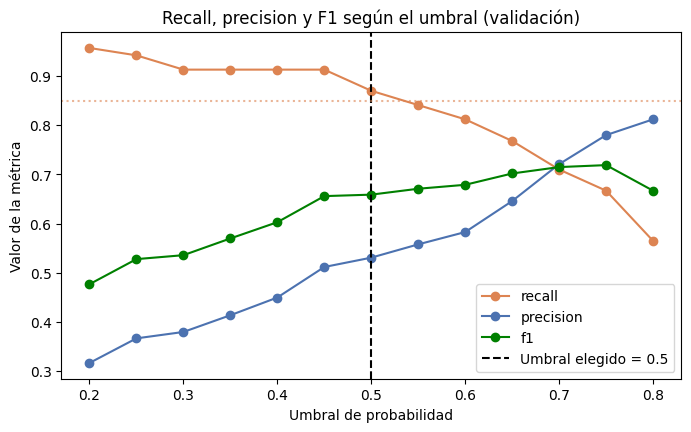

,accuracy,recall,precision,f1,auc_roc,casos_marcados
umbral,,,,,,
0.20,0.597,0.957,0.317,0.477,0.92,208
0.25,0.678,0.942,0.367,0.528,0.92,177
0.30,0.697,0.913,0.380,0.536,0.92,166
0.35,0.736,0.913,0.414,0.570,0.92,152
0.40,0.769,0.913,0.450,0.603,0.92,140
0.45,0.817,0.913,0.512,0.656,0.92,123
0.50,0.828,0.870,0.531,0.659,0.92,113
0.55,0.842,0.841,0.558,0.671,0.92,104
0.60,0.853,0.812,0.583,0.679,0.92,96


In [23]:
# --- CELDA 23: barrido de umbrales en validación ---
RECALL_OBJETIVO = 0.85
prob_val = modelo_final.predict_proba(X_val)[:, 1]

umbrales = np.round(np.arange(0.20, 0.81, 0.05), 2)
filas = []
for u in umbrales:
    m = calcular_metricas(y_val, prob_val, umbral=u)
    m["umbral"] = u
    m["casos_marcados"] = int((prob_val >= u).sum())
    filas.append(m)
tabla_umbrales = pd.DataFrame(filas).set_index("umbral").round(3)

cumplen = tabla_umbrales[tabla_umbrales["recall"] >= RECALL_OBJETIVO]
UMBRAL = float(cumplen.index.max()) if len(cumplen) else 0.5
print(f"Umbral elegido: {UMBRAL}")

fig, ax = plt.subplots(figsize=(8, 4.5))
for metrica, color in [("recall", COLOR_ABANDONA), ("precision", COLOR_CONTINUA), ("f1", "green")]:
    ax.plot(tabla_umbrales.index, tabla_umbrales[metrica], marker="o", label=metrica, color=color)
ax.axvline(UMBRAL, color="black", ls="--", label=f"Umbral elegido = {UMBRAL}")
ax.axhline(RECALL_OBJETIVO, color=COLOR_ABANDONA, ls=":", alpha=0.6)
ax.set_title("Recall, precision y F1 según el umbral (validación)")
ax.set_xlabel("Umbral de probabilidad")
ax.set_ylabel("Valor de la métrica")
ax.legend()
plt.show()
tabla_umbrales

## 8. Evaluación final en el conjunto de prueba

Ahora, y **solo ahora**, usamos los datos de prueba, que el modelo no ha visto nunca. Así medimos su
rendimiento real con estudiantes nuevos.

In [25]:
# --- CELDA 24: métricas en prueba ---
prob_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= UMBRAL).astype(int)

metricas_test = calcular_metricas(y_test, prob_test, umbral=UMBRAL)
print(f"Umbral utilizado: {UMBRAL}\n")
for nombre, valor in metricas_test.items():
    print(f"{nombre:10s}: {valor:.3f}")

print("\nInforme de clasificación completo:")
print(classification_report(y_test, pred_test, target_names=["Continúa", "Abandona"]))

Umbral utilizado: 0.5

accuracy  : 0.831
recall    : 0.797
precision : 0.539
f1        : 0.643
auc_roc   : 0.910

Informe de clasificación completo:
              precision    recall  f1-score   support

    Continúa       0.95      0.84      0.89       291
    Abandona       0.54      0.80      0.64        69

    accuracy                           0.83       360
   macro avg       0.74      0.82      0.77       360
weighted avg       0.87      0.83      0.84       360



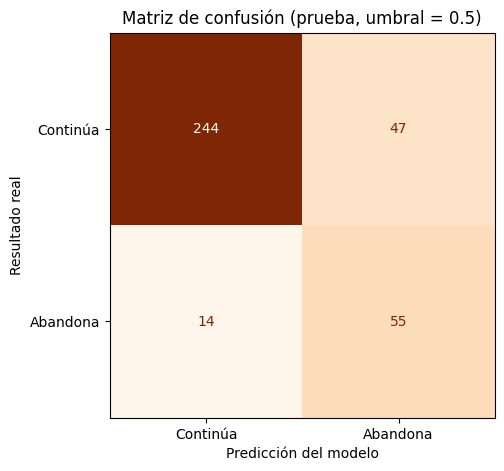

✅ Verdaderos positivos (abandonos detectados):     55
❌ Falsos negativos (abandonos NO detectados):       14
⚠️  Falsos positivos (alertas a quien no abandona):  47
✅ Verdaderos negativos (continúan y no se marcan):  244

Carga para tutoría: 102 estudiantes marcados de 360 (28%); 55 de ellos abandonarían de verdad.


In [26]:
# --- CELDA 25: matriz de confusión ---
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["Continúa", "Abandona"],
    cmap="Oranges", colorbar=False, ax=ax)
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Resultado real")
ax.set_title(f"Matriz de confusión (prueba, umbral = {UMBRAL})")
ax.grid(False)
plt.show()

vn, fp, fn, vp = confusion_matrix(y_test, pred_test).ravel()
print(f"✅ Verdaderos positivos (abandonos detectados):     {vp}")
print(f"❌ Falsos negativos (abandonos NO detectados):       {fn}")
print(f"⚠️  Falsos positivos (alertas a quien no abandona):  {fp}")
print(f"✅ Verdaderos negativos (continúan y no se marcan):  {vn}")
print(f"\nCarga para tutoría: {vp + fp} estudiantes marcados de {len(y_test)} "
      f"({(vp + fp) / len(y_test):.0%}); {vp} de ellos abandonarían de verdad.")

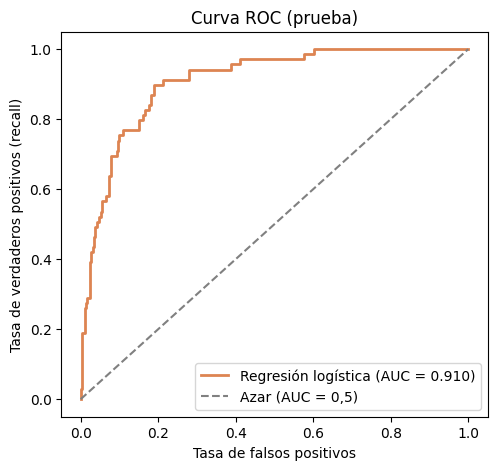

In [27]:
# --- CELDA 26: curva ROC ---
# roc_curve calcula la tasa de falsos positivos y de verdaderos positivos para cada umbral
tasa_fp, tasa_vp, _ = roc_curve(y_test, prob_test)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(tasa_fp, tasa_vp, color=COLOR_ABANDONA, lw=2,
        label=f"Regresión logística (AUC = {metricas_test['auc_roc']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="grey", label="Azar (AUC = 0,5)")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("Curva ROC (prueba)")
ax.legend(loc="lower right")
plt.show()

**Cómo leer estas métricas:**
- **Recall**: de cada 100 estudiantes que realmente abandonan, cuántos detecta el modelo. Es nuestra
  métrica principal.
- **Precision**: de cada 100 estudiantes marcados como "en riesgo", cuántos abandonarían de verdad.
  Nos dice cuánta carga de seguimiento tendrá el equipo de tutoría.
- **Accuracy**: aciertos totales. Útil como referencia, pero engaña con clases desbalanceadas.
- **F1**: equilibrio entre precision y recall.
- **AUC-ROC**: capacidad de ordenar a los estudiantes por riesgo (1 = perfecto, 0,5 = azar).

## 9. Interpretación de los coeficientes

Como las variables están estandarizadas, el **coeficiente** indica el efecto de aumentar la variable
**una desviación típica**, manteniendo el resto constante:

- **Coeficiente positivo** → aumenta los *log-odds* (y por tanto la probabilidad) de abandono.
- **Coeficiente negativo** → reduce el riesgo (factor protector).
- **Odds ratio = e^coeficiente**: por cuánto se multiplican las "probabilidades a favor" de abandonar.

In [29]:
# --- CELDA 27: tabla de coeficientes ---
nombres = modelo_final.named_steps["preprocesado"].get_feature_names_out()
nombres = [n.replace("num__", "").replace("cat__", "") for n in nombres]
coeficientes = modelo_final.named_steps["regresion"].coef_[0]

tabla_coef = pd.DataFrame({"variable": nombres, "coeficiente": coeficientes})
tabla_coef["odds_ratio"] = np.exp(tabla_coef["coeficiente"])
tabla_coef["efecto"] = np.where(tabla_coef["coeficiente"] > 0, "↑ aumenta riesgo", "↓ reduce riesgo")
tabla_coef = tabla_coef.reindex(tabla_coef["coeficiente"].abs().sort_values(ascending=False).index)
tabla_coef.round(3).reset_index(drop=True)

,variable,coeficiente,odds_ratio,efecto
0,asistencia_ultimos_30_dias_pct,-0.303,0.738,↓ reduce riesgo
1,ha_repetido_curso,0.284,1.328,↑ aumenta riesgo
2,acoso_frecuencia_0_3,0.281,1.325,↑ aumenta riesgo
3,dificultad_economica_hogar_1_5,0.262,1.299,↑ aumenta riesgo
4,materias_suspensas_trimestre_anterior,0.256,1.291,↑ aumenta riesgo
5,satisfaccion_programa_1_5,-0.198,0.821,↓ reduce riesgo
6,intencion_continuar_estudios_1_5,-0.197,0.821,↓ reduce riesgo
7,relacion_docentes_1_5,-0.193,0.824,↓ reduce riesgo
8,nota_media_trimestre_anterior_0_10,-0.184,0.832,↓ reduce riesgo
9,horas_estudio_semana,-0.166,0.847,↓ reduce riesgo


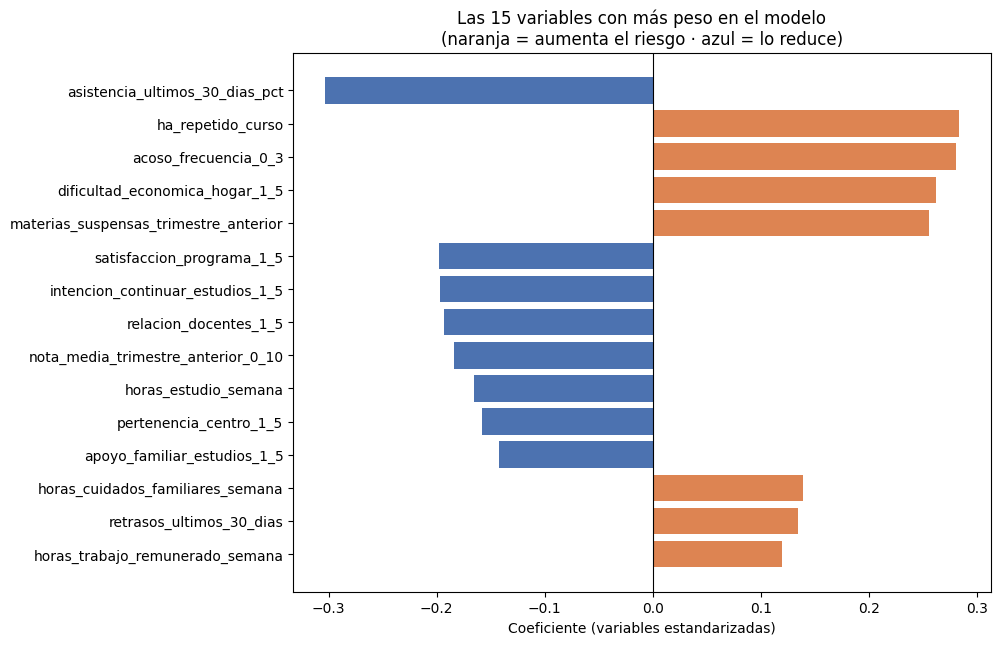

In [30]:
# --- CELDA 28: gráfico de coeficientes ordenados por magnitud ---
top = tabla_coef.head(15).iloc[::-1]   # las 15 más influyentes (invertimos para el gráfico)
colores = [COLOR_ABANDONA if c > 0 else COLOR_CONTINUA for c in top["coeficiente"]]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["variable"], top["coeficiente"], color=colores)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Las 15 variables con más peso en el modelo\n"
             "(naranja = aumenta el riesgo · azul = lo reduce)")
ax.set_xlabel("Coeficiente (variables estandarizadas)")
plt.show()

## 10. Auditoría de equidad

El modelo **no** usa las variables sensibles, pero aun así podría fallar más con algunos grupos.
Comprobamos el **recall** y los **falsos negativos** por grupo en el conjunto de prueba.

> Nota: algunos grupos tienen pocos estudiantes que abandonan, así que las diferencias pequeñas
> pueden deberse al azar. Mostramos el número de casos para interpretarlo con prudencia.

In [31]:
# --- CELDA 29: recall por grupo sensible ---
auditoria = prueba[VARIABLES_AUDITORIA + [OBJETIVO]].copy()
auditoria["prediccion"] = pred_test

def metricas_por_grupo(datos, variable):
    filas = []
    for grupo, sub in datos.groupby(variable):
        abandonos = sub[sub[OBJETIVO] == 1]
        filas.append({
            "variable": variable, "grupo": grupo, "estudiantes": len(sub),
            "abandonos_reales": len(abandonos),
            "recall": (abandonos["prediccion"] == 1).mean() if len(abandonos) else np.nan,
            "falsos_negativos": int((abandonos["prediccion"] == 0).sum()),
        })
    return filas

filas = []
for var in ["sexo_declarado", "nacido_fuera_espana", "necesidad_apoyo_educativo", "titularidad_centro"]:
    filas += metricas_por_grupo(auditoria, var)
tabla_equidad = pd.DataFrame(filas).round(3)
tabla_equidad

,variable,grupo,estudiantes,abandonos_reales,recall,falsos_negativos
0,sexo_declarado,Hombre,186,32,0.719,9
1,sexo_declarado,Mujer,168,36,0.861,5
2,sexo_declarado,No binario,4,0,NaN,0
3,sexo_declarado,Prefiere no responder,2,1,1.000,0
4,nacido_fuera_espana,0,303,54,0.759,13
5,nacido_fuera_espana,1,57,15,0.933,1
6,necesidad_apoyo_educativo,0,330,60,0.783,13
7,necesidad_apoyo_educativo,1,30,9,0.889,1
8,titularidad_centro,Concertado,124,23,0.783,5
9,titularidad_centro,Privado,20,2,1.000,0


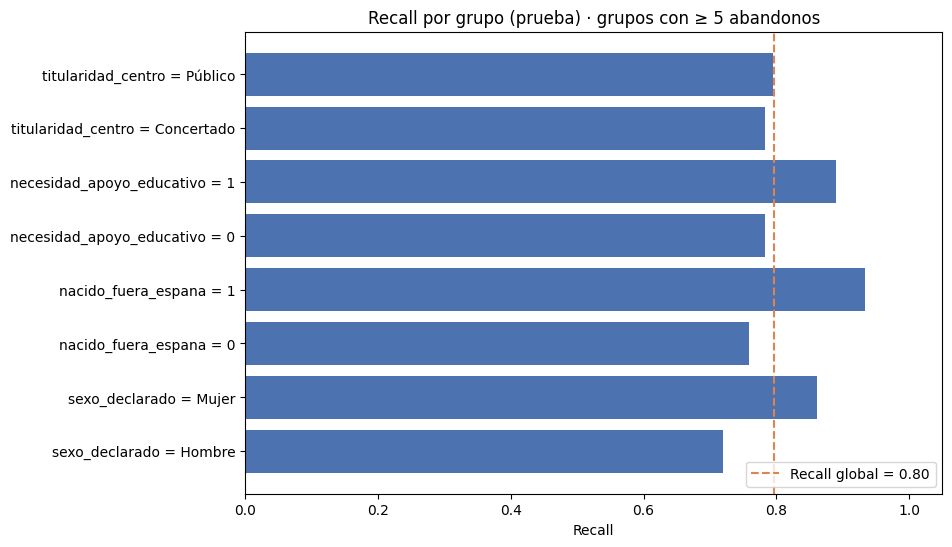

In [32]:
# --- CELDA 30: gráfico de recall por grupo ---
datos_graf = tabla_equidad[tabla_equidad["abandonos_reales"] >= 5].copy()   # grupos con datos suficientes
datos_graf["etiqueta"] = datos_graf["variable"] + " = " + datos_graf["grupo"].astype(str)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(datos_graf["etiqueta"], datos_graf["recall"], color=COLOR_CONTINUA)
ax.axvline(metricas_test["recall"], color=COLOR_ABANDONA, ls="--",
           label=f"Recall global = {metricas_test['recall']:.2f}")
ax.set_xlim(0, 1.05)
ax.set_title("Recall por grupo (prueba) · grupos con ≥ 5 abandonos")
ax.set_xlabel("Recall")
ax.legend(loc="lower right")
plt.show()

In [33]:
# --- CELDA 31: recall por comunidad autónoma (validación + prueba para tener más casos) ---
val_test = pd.concat([validacion, prueba])
val_test = val_test.assign(prediccion=(modelo_final.predict_proba(val_test[PREDICTORAS])[:, 1] >= UMBRAL).astype(int))
tabla_ccaa = pd.DataFrame(metricas_por_grupo(val_test, "comunidad_autonoma"))
tabla_ccaa.sort_values("recall").round(3).reset_index(drop=True)

,variable,grupo,estudiantes,abandonos_reales,recall,falsos_negativos
0,comunidad_autonoma,La Rioja,6,1,0.000,1
1,comunidad_autonoma,Canarias,32,9,0.667,3
2,comunidad_autonoma,Extremadura,20,3,0.667,1
3,comunidad_autonoma,Región de Murcia,20,3,0.667,1
4,comunidad_autonoma,Comunidad de Madrid,105,22,0.727,6
5,comunidad_autonoma,País Vasco,25,4,0.750,1
6,comunidad_autonoma,Comunidad Foral de Navarra,21,5,0.800,1
7,comunidad_autonoma,Comunitat Valenciana,70,16,0.812,3
8,comunidad_autonoma,Castilla-La Mancha,29,7,0.857,1
9,comunidad_autonoma,Andalucía,133,26,0.885,3


## 11. Conclusiones y recomendaciones

*(Las cifras se recalculan al ejecutar el notebook; abajo se resumen los resultados obtenidos.)*

In [34]:
# --- CELDA 32: resumen final de resultados ---
print("RESUMEN DEL MODELO")
print("=" * 50)
print(f"Modelo: regresión logística · class_weight='balanced' · C={MEJOR_C}")
print(f"Umbral de decisión: {UMBRAL}")
print(f"Recall    (abandonos detectados): {metricas_test['recall']:.1%}")
print(f"Precision (alertas acertadas):    {metricas_test['precision']:.1%}")
print(f"Accuracy:                         {metricas_test['accuracy']:.1%}")
print(f"F1-score:                         {metricas_test['f1']:.3f}")
print(f"AUC-ROC:                          {metricas_test['auc_roc']:.3f}")
print("\nFactores que MÁS AUMENTAN el riesgo:")
for v in tabla_coef[tabla_coef["coeficiente"] > 0].head(5)["variable"]:
    print("  ↑", v)
print("Factores que MÁS PROTEGEN:")
for v in tabla_coef[tabla_coef["coeficiente"] < 0].head(5)["variable"]:
    print("  ↓", v)

RESUMEN DEL MODELO
Modelo: regresión logística · class_weight='balanced' · C=0.01
Umbral de decisión: 0.5
Recall    (abandonos detectados): 79.7%
Precision (alertas acertadas):    53.9%
Accuracy:                         83.1%
F1-score:                         0.643
AUC-ROC:                          0.910

Factores que MÁS AUMENTAN el riesgo:
  ↑ ha_repetido_curso
  ↑ acoso_frecuencia_0_3
  ↑ dificultad_economica_hogar_1_5
  ↑ materias_suspensas_trimestre_anterior
  ↑ horas_cuidados_familiares_semana
Factores que MÁS PROTEGEN:
  ↓ asistencia_ultimos_30_dias_pct
  ↓ satisfaccion_programa_1_5
  ↓ intencion_continuar_estudios_1_5
  ↓ relacion_docentes_1_5
  ↓ nota_media_trimestre_anterior_0_10


### 11.1 Resultados del modelo (conjunto de prueba, umbral 0,5)

| Métrica | Valor | Qué significa para EduFuture |
|---|---|---|
| **Recall** | **≈ 80 %** | De cada 10 estudiantes que abandonarán, el modelo detecta 8 a tiempo |
| Precision | ≈ 54 % | De cada 2 alertas, aproximadamente 1 corresponde a un abandono real |
| Accuracy | ≈ 83 % | Aciertos totales (referencia; engaña con clases desbalanceadas) |
| F1-score | ≈ 0,64 | Equilibrio entre recall y precision |
| AUC-ROC | ≈ 0,91 | Muy buena capacidad para ordenar a los estudiantes por riesgo |

- **Carga operativa:** el modelo marca a ≈ 28 % del alumnado (102 de 360). Es asumible para un
  programa de tutoría preventiva y concentra el esfuerzo donde está el riesgo.
- **Sin sobreajuste:** el AUC es casi igual en entrenamiento (0,91), validación (0,92) y prueba (0,91).
- En prueba el recall (0,80) queda algo por debajo del objetivo fijado en validación (0,85): con solo
  69 abandonos en cada conjunto, unos pocos casos mueven mucho la métrica. Si EduFuture prefiere
  detectar todavía más casos, puede **bajar el umbral a 0,45**, aceptando revisar más falsas alarmas.

### 11.2 ¿Qué factores explican el abandono?

| Aumentan el riesgo ↑ | Protegen ↓ |
|---|---|
| Haber repetido curso | **Asistencia** alta (el factor con más peso) |
| Sufrir **acoso** con frecuencia | Satisfacción con el programa |
| **Dificultad económica** en el hogar | Intención de continuar estudiando |
| Materias suspensas | Buena relación con el profesorado |
| Horas de cuidados familiares y de trabajo | Nota media y horas de estudio |
| Retrasos frecuentes | Pertenencia al centro y apoyo familiar |

La mayoría de estas señales son **modificables**: el abandono no es un destino, se puede prevenir.

### 11.3 Recomendaciones para reducir la deserción

1. **Alerta temprana de asistencia:** revisar cada mes a quien baje del 85 % de asistencia o acumule
   retrasos. Contacto con la familia y revisión de barreras (transporte, horarios, cuidados).
2. **Refuerzo académico:** plan de recuperación con seguimiento quincenal para quien tenga 2 o más
   suspensos o haya repetido curso.
3. **Orientación vocacional:** cuando la satisfacción, la utilidad percibida o la intención de
   continuar son bajas, revisar si el itinerario (Bachillerato, FP…) encaja con el estudiante.
4. **Apoyo socioeconómico:** información sobre becas, flexibilidad horaria y conciliación para quien
   tiene dificultades económicas, trabaja o cuida de familiares.
5. **Convivencia y bienestar:** activar el protocolo antiacoso y el apoyo psicoeducativo; trabajar la
   pertenencia al centro y la relación con el profesorado (tutorías, mentoría entre iguales).
6. **Uso del modelo:** ejecutarlo al inicio de cada trimestre, priorizar por probabilidad y medir si
   las intervenciones reducen el abandono.

### 11.4 Equidad y uso responsable

- El modelo **no utiliza** sexo, origen, necesidad de apoyo educativo, titularidad ni territorio.
- Aun así, la auditoría muestra que el recall es **menor en hombres (≈ 0,72) que en mujeres (≈ 0,86)**:
  a los chicos en riesgo se les escapan más casos. Antes de usar el modelo en un entorno real habría que
  investigar la causa (por ejemplo, señales de riesgo distintas) y, si procede, ajustar el umbral o
  añadir revisión adicional.
- En comunidades autónomas con pocos casos las diferencias no son concluyentes.
- **La predicción activa una revisión humana y una oferta de apoyo; nunca una sanción ni una exclusión.**
  La probabilidad describe un riesgo estadístico, no la capacidad ni el compromiso de una persona.